# 02 · Demand patterns

The Syntetos-Boylan classes sort each series by two numbers from its training history:

- **ADI**, the average interval between sales (how often it sells); the cut-off is 1.32 days;
- **CV²**, the squared coefficient of variation of the non-zero sales (how much the size
  varies when it sells); the cut-off is 0.49.

| | CV² < 0.49 | CV² ≥ 0.49 |
|---|---|---|
| **ADI < 1.32** | smooth | erratic |
| **ADI ≥ 1.32** | intermittent | lumpy |

Croston, SBA, TSB, ADIDA and IMAPA were designed for the intermittent and lumpy classes. This
notebook reads only committed result tables (`results/tables`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import pandas as pd

from forecasting.viz import plots

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
%matplotlib inline
%config InlineBackend.figure_format = "png"

In [2]:
tables = ROOT / "results" / "tables"
# Each series' ADI, CV² and class, from its training history (one row per series).
series = pd.read_csv(tables / "m5_series_classes.csv.gz")
counts = series["demand_class"].value_counts()
print((counts / counts.sum()).round(3).to_dict())
print(counts.to_dict())

{'intermittent': 0.727, 'lumpy': 0.183, 'smooth': 0.062, 'erratic': 0.028}
{'intermittent': 22155, 'lumpy': 5572, 'smooth': 1903, 'erratic': 860}


Nearly three quarters of M5's series are intermittent: they sell on fewer than three days in
four, in small, steady amounts. Only 6% are smooth.

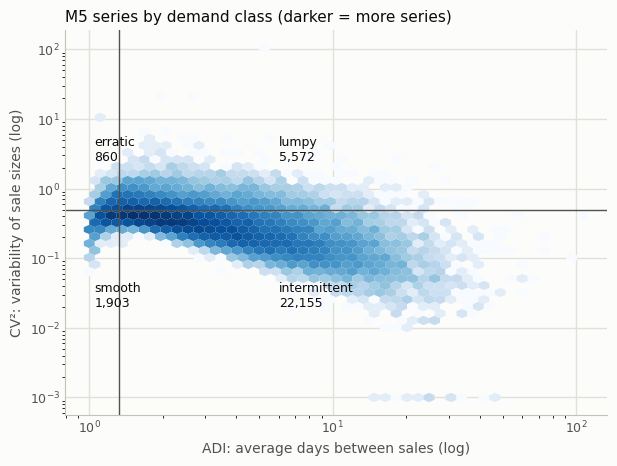

In [3]:
fig, ax = plt.subplots(figsize=(7, 5), facecolor=plots.SURFACE)
plots.style_axes(ax, grid_axis="both")
ok = series[["ADI", "CV2"]].dropna()
hb = ax.hexbin(
    ok["ADI"],
    ok["CV2"].clip(1e-3),
    xscale="log",
    yscale="log",
    gridsize=45,
    bins="log",
    cmap="Blues",
    mincnt=1,
    linewidths=0,
)
ax.axvline(1.32, color=plots.INK_2, linewidth=1)
ax.axhline(0.49, color=plots.INK_2, linewidth=1)
for name, (x, y) in {
    "smooth": (1.05, 0.02),
    "intermittent": (6, 0.02),
    "erratic": (1.05, 2.5),
    "lumpy": (6, 2.5),
}.items():
    ax.text(x, y, f"{name}\n{counts.get(name, 0):,}", color=plots.INK, fontsize=9)
ax.set_xlabel("ADI: average days between sales (log)", color=plots.INK_2)
ax.set_ylabel("CV²: variability of sale sizes (log)", color=plots.INK_2)
ax.set_title(
    "M5 series by demand class (darker = more series)", loc="left", color=plots.INK, fontsize=11
)
plt.show()

### Which models win which class?

The median RMSSE per class on the M5 test, for one model from each family. Lower is better.
The blends are absent because they are scored only through WRMSSE, not per series.

In [4]:
by_class = pd.concat(pd.read_csv(p) for p in tables.glob("*_m5_competition_by_class.csv"))
by_class = by_class.drop_duplicates("model").set_index("model")
by_class.columns = [c.split(" ")[0] for c in by_class.columns]
picks = [
    "LightGBM-store",
    "CatBoost-l2",
    "N-BEATS-tuned-3w",
    "Chronos-2",
    "AutoETS",
    "CrostonSBA",
    "TSB",
    "ADIDA",
    "IMAPA",
    "HistoricAverage",
    "SeasonalNaive",
    "Zero",
]
table = by_class.loc[picks, ["smooth", "erratic", "intermittent", "lumpy"]]
table.style.format("{:.3f}").highlight_min(axis=0, props="font-weight: bold")

,smooth,erratic,intermittent,lumpy
model,,,,
LightGBM-store,0.684,0.595,0.717,0.625
CatBoost-l2,0.689,0.598,0.715,0.627
N-BEATS-tuned-3w,0.689,0.601,0.715,0.629
Chronos-2,0.679,0.598,0.714,0.623
AutoETS,0.688,0.625,0.719,0.635
CrostonSBA,0.701,0.618,0.721,0.632
TSB,0.716,0.619,0.749,0.648
ADIDA,0.706,0.620,0.723,0.635
IMAPA,0.706,0.620,0.725,0.638


In [5]:
best = by_class[["smooth", "erratic", "intermittent", "lumpy"]].idxmin()
print("best model per class, over every model in the benchmark:")
for c, m in best.items():
    print(f"  {c:<12} {m:<22} {by_class.loc[m, c]:.3f}")

best model per class, over every model in the benchmark:
  smooth       Chronos-2              0.679
  erratic      LightGBM-store-direct  0.595
  intermittent HistoricAverage        0.710
  lumpy        Chronos-2              0.623


**Reading it.** Per series, the classes barely separate the strong models: trees, tuned
N-BEATS and Chronos-2 are within about 0.01 of each other in every class. The Croston family
is competitive on intermittent series, the case it was built for, but does not lead. A simple
historic average is level with the best models on intermittent series: when a product sells
one unit every few days, there is little pattern left to learn. The differences that decide
WRMSSE are in the aggregates (notebook 03), not here.